# Seed-to-seed agreement of DataDecide token IF scores

For every ordered pair of seeds within one corpus (ref -> other), tokens are binned by the ref seed's
percentile (0 = highest influence). Per bin we show how the other seed scores them:

- **z difference**: z_other - z_ref, scores mapped to normal quantiles by rank
- **rank change**: pct_ref - pct_other (percentile points; negative = other ranks it lower)
- **raw difference**: score_other - score_ref
- **relative change**: (other - ref) / ((|ref| + |other|) / 2), bounded in [-2, 2]
- **sign flips**: fraction of tokens whose score sign differs between the seeds

**Grey = noise model**: other seed = same true value + independent Gaussian noise, with the same overall
correlation (rho, in z space) and the same score distribution as the real other seed. Under it,
z_other | z_ref ~ N(rho * z_ref, 1 - rho²), so the z difference is centred on -(1 - rho) * z_ref with the
same spread in every bin. This is the selection effect of binning on the ref seed (regression to the
mean). Gaps between real and grey = structure beyond uniform noise.

In [1]:
from itertools import permutations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

SCORES = Path("/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/scped_IFS/datadecide_extract/token-scores/datadecide_token_scores.parquet")
CORPORA = {"dolma17": ["dolma17_s0", "dolma17_s2", "dolma17_s3"],
           "dclm": ["dclm_s0", "dclm_s2", "dclm_s3"]}
EDGES = [0, 0.5, 1, 2, 5, 10, 25, 50, 75, 90, 95, 98, 99, 99.5, 100]
LABELS = [f"{lo:g}-{hi:g}" for lo, hi in zip(EDGES[:-1], EDGES[1:])]
PANELS = [("z", "z difference (other - ref)"),
          ("rank", "rank change (pct points, - = other ranks lower)"),
          ("raw", "raw difference (other - ref)"),
          ("rel", "relative change (other - ref) / mean |score|")]

dd = pd.read_parquet(SCORES)
print(f"{len(dd)} tokens, {dd['document'].nunique()} documents")

395841 tokens, 5900 documents


## Per-pair frame: real other seed and its noise-model twin

The fake other seed is `rho * z_ref + sqrt(1 - rho²) * noise`, then mapped by rank onto the real
other seed's sorted scores, so it has the same score distribution (heavy tails, share of negatives).

In [2]:
def percentile(scores):
    """0 = highest score, 100 = lowest."""
    return 100 * (scores.rank(ascending=False).to_numpy() - 0.5) / len(scores)


def pair_frame(ref, other, rng):
    pct_ref, pct_other = percentile(ref), percentile(other)
    z_ref, z_other = norm.ppf(1 - pct_ref / 100), norm.ppf(1 - pct_other / 100)
    rho = np.corrcoef(z_ref, z_other)[0, 1]

    # noise model: fake other seed with the same rho, mapped onto the real other seed's scores
    z_fake = rho * z_ref + np.sqrt(1 - rho**2) * rng.standard_normal(len(ref))
    order = np.argsort(np.argsort(-z_fake))
    raw_fake = np.sort(other.to_numpy())[::-1][order]
    pct_fake = 100 * (order + 0.5) / len(ref)

    out = []
    for kind, o_raw, o_pct, o_z in [("real", other.to_numpy(), pct_other, z_other),
                                    ("noise model", raw_fake, pct_fake, z_fake)]:
        r_raw = ref.to_numpy()
        out.append(pd.DataFrame({
            "kind": kind,
            "bin": pd.cut(pct_ref, EDGES, labels=LABELS, include_lowest=True),
            "z": o_z - z_ref,
            "rank": pct_ref - o_pct,
            "raw": o_raw - r_raw,
            "rel": (o_raw - r_raw) / ((np.abs(r_raw) + np.abs(o_raw)) / 2 + 1e-12),
            "flip": np.sign(o_raw) != np.sign(r_raw),
        }))
    return pd.concat(out), rho

## All ordered seed pairs per corpus

The 6 ordered pairs are pooled per corpus (each seed pair appears twice, once per direction).

In [3]:
rng = np.random.default_rng(0)
RESULTS, RHOS = {}, {}
for corpus, seeds in CORPORA.items():
    frames = []
    for ref, other in permutations(seeds, 2):
        f, RHOS[f"{ref}->{other}"] = pair_frame(dd[ref], dd[other], rng)
        frames.append(f.assign(pair=f"{ref}->{other}"))
    RESULTS[corpus] = pd.concat(frames)

pd.Series(RHOS, name="rho (z space)").round(3)

dolma17_s0->dolma17_s2    0.401
dolma17_s0->dolma17_s3    0.390
dolma17_s2->dolma17_s0    0.401
dolma17_s2->dolma17_s3    0.410
dolma17_s3->dolma17_s0    0.390
dolma17_s3->dolma17_s2    0.410
dclm_s0->dclm_s2          0.483
dclm_s0->dclm_s3          0.435
dclm_s2->dclm_s0          0.483
dclm_s2->dclm_s3          0.451
dclm_s3->dclm_s0          0.435
dclm_s3->dclm_s2          0.451
Name: rho (z space), dtype: float64

In [4]:
for corpus, res in RESULTS.items():
    summary = res.groupby(["bin", "kind"], observed=True).agg(
        n=("z", "size"), z_median=("z", "median"),
        z_iqr=("z", lambda s: s.quantile(0.75) - s.quantile(0.25)),
        rank_median=("rank", "median"), flip=("flip", "mean")).unstack("kind")
    print(f"=== {corpus} ===")
    display(summary.round(3))

=== dolma17 ===


n            z_median              z_iqr         \
kind     noise model    real noise model   real noise model   real   
bin                                                                  
0-0.5          11874   11874      -1.735 -0.830       1.261  1.519   
0.5-1          11874   11874      -1.478 -0.773       1.240  1.615   
1-2            23754   23754      -1.291 -0.724       1.232  1.632   
2-5            71250   71250      -1.103 -0.690       1.234  1.990   
5-10          118752  118752      -0.866 -0.624       1.241  1.883   
10-25         356256  356256      -0.565 -0.421       1.240  1.507   
25-50         593766  593766      -0.193 -0.094       1.249  0.839   
50-75         593760  593760       0.192  0.065       1.244  0.629   
75-90         356256  356256       0.570  0.370       1.246  1.593   
90-95         118752  118752       0.873  0.535       1.243  1.758   
95-98          71250   71250       1.096  0.661       1.239  1.434   
98-99          23754   23754       1.297  0.795       1.226  1.319   
99-99.5        11874   11874       1.464  0.821       1.226  1.321   
99.5-100       11874   11874       1.721  0.847       1.262  1.387   

         rank_median                flip         
kind     noise model    real noise model   real  
bin                                              
0-0.5        -12.191  -1.830       0.070  0.171  
0.5-1        -15.994  -4.062       0.095  0.202  
1-2          -17.434  -5.879       0.111  0.219  
2-5          -20.008  -9.392       0.146  0.256  
5-10         -20.599 -13.091       0.189  0.293  
10-25        -17.700 -12.635       0.252  0.319  
25-50         -7.393  -3.571       0.347  0.302  
50-75          7.286   2.489       0.488  0.449  
75-90         17.820  10.703       0.436  0.399  
90-95         20.815  10.581       0.355  0.300  
95-98         19.785   8.772       0.294  0.247  
98-99         17.490   6.907       0.241  0.214  
99-99.5       15.759   4.613       0.205  0.183  
99.5-100      11.944   1.978       0.159  0.155

=== dclm ===


n            z_median              z_iqr         \
kind     noise model    real noise model   real noise model   real   
bin                                                                  
0-0.5          11874   11874      -1.586 -0.491       1.210  0.969   
0.5-1          11874   11874      -1.322 -0.551       1.207  1.088   
1-2            23754   23754      -1.182 -0.548       1.198  1.213   
2-5            71250   71250      -0.995 -0.549       1.208  1.371   
5-10          118752  118752      -0.787 -0.533       1.204  1.800   
10-25         356256  356256      -0.519 -0.367       1.209  1.507   
25-50         593764  593764      -0.177 -0.135       1.207  0.756   
50-75         593762  593762       0.174  0.116       1.208  0.690   
75-90         356256  356256       0.512  0.343       1.206  1.540   
90-95         118752  118752       0.786  0.499       1.204  1.643   
95-98          71250   71250       0.990  0.607       1.206  1.254   
98-99          23754   23754       1.174  0.680       1.209  1.235   
99-99.5        11874   11874       1.341  0.768       1.193  1.230   
99.5-100       11874   11874       1.571  0.857       1.220  1.272   

         rank_median                flip         
kind     noise model    real noise model   real  
bin                                              
0-0.5         -9.188  -0.642       0.058  0.073  
0.5-1        -12.504  -2.225       0.089  0.122  
1-2          -14.462  -3.665       0.107  0.161  
2-5          -16.858  -6.652       0.147  0.218  
5-10         -17.854 -10.598       0.196  0.280  
10-25        -15.931 -10.705       0.275  0.333  
25-50         -6.686  -5.202       0.390  0.361  
50-75          6.666   4.483       0.478  0.466  
75-90         15.778   9.874       0.357  0.356  
90-95         17.968   9.690       0.270  0.268  
95-98         16.764   7.751       0.212  0.218  
98-99         14.426   5.257       0.163  0.178  
99-99.5       12.858   4.020       0.132  0.154  
99.5-100       9.149   1.965       0.085  0.123

## Distributions per bin

Boxes = interquartile range, whiskers = 5th-95th percentile, grey = noise model, blue = real.

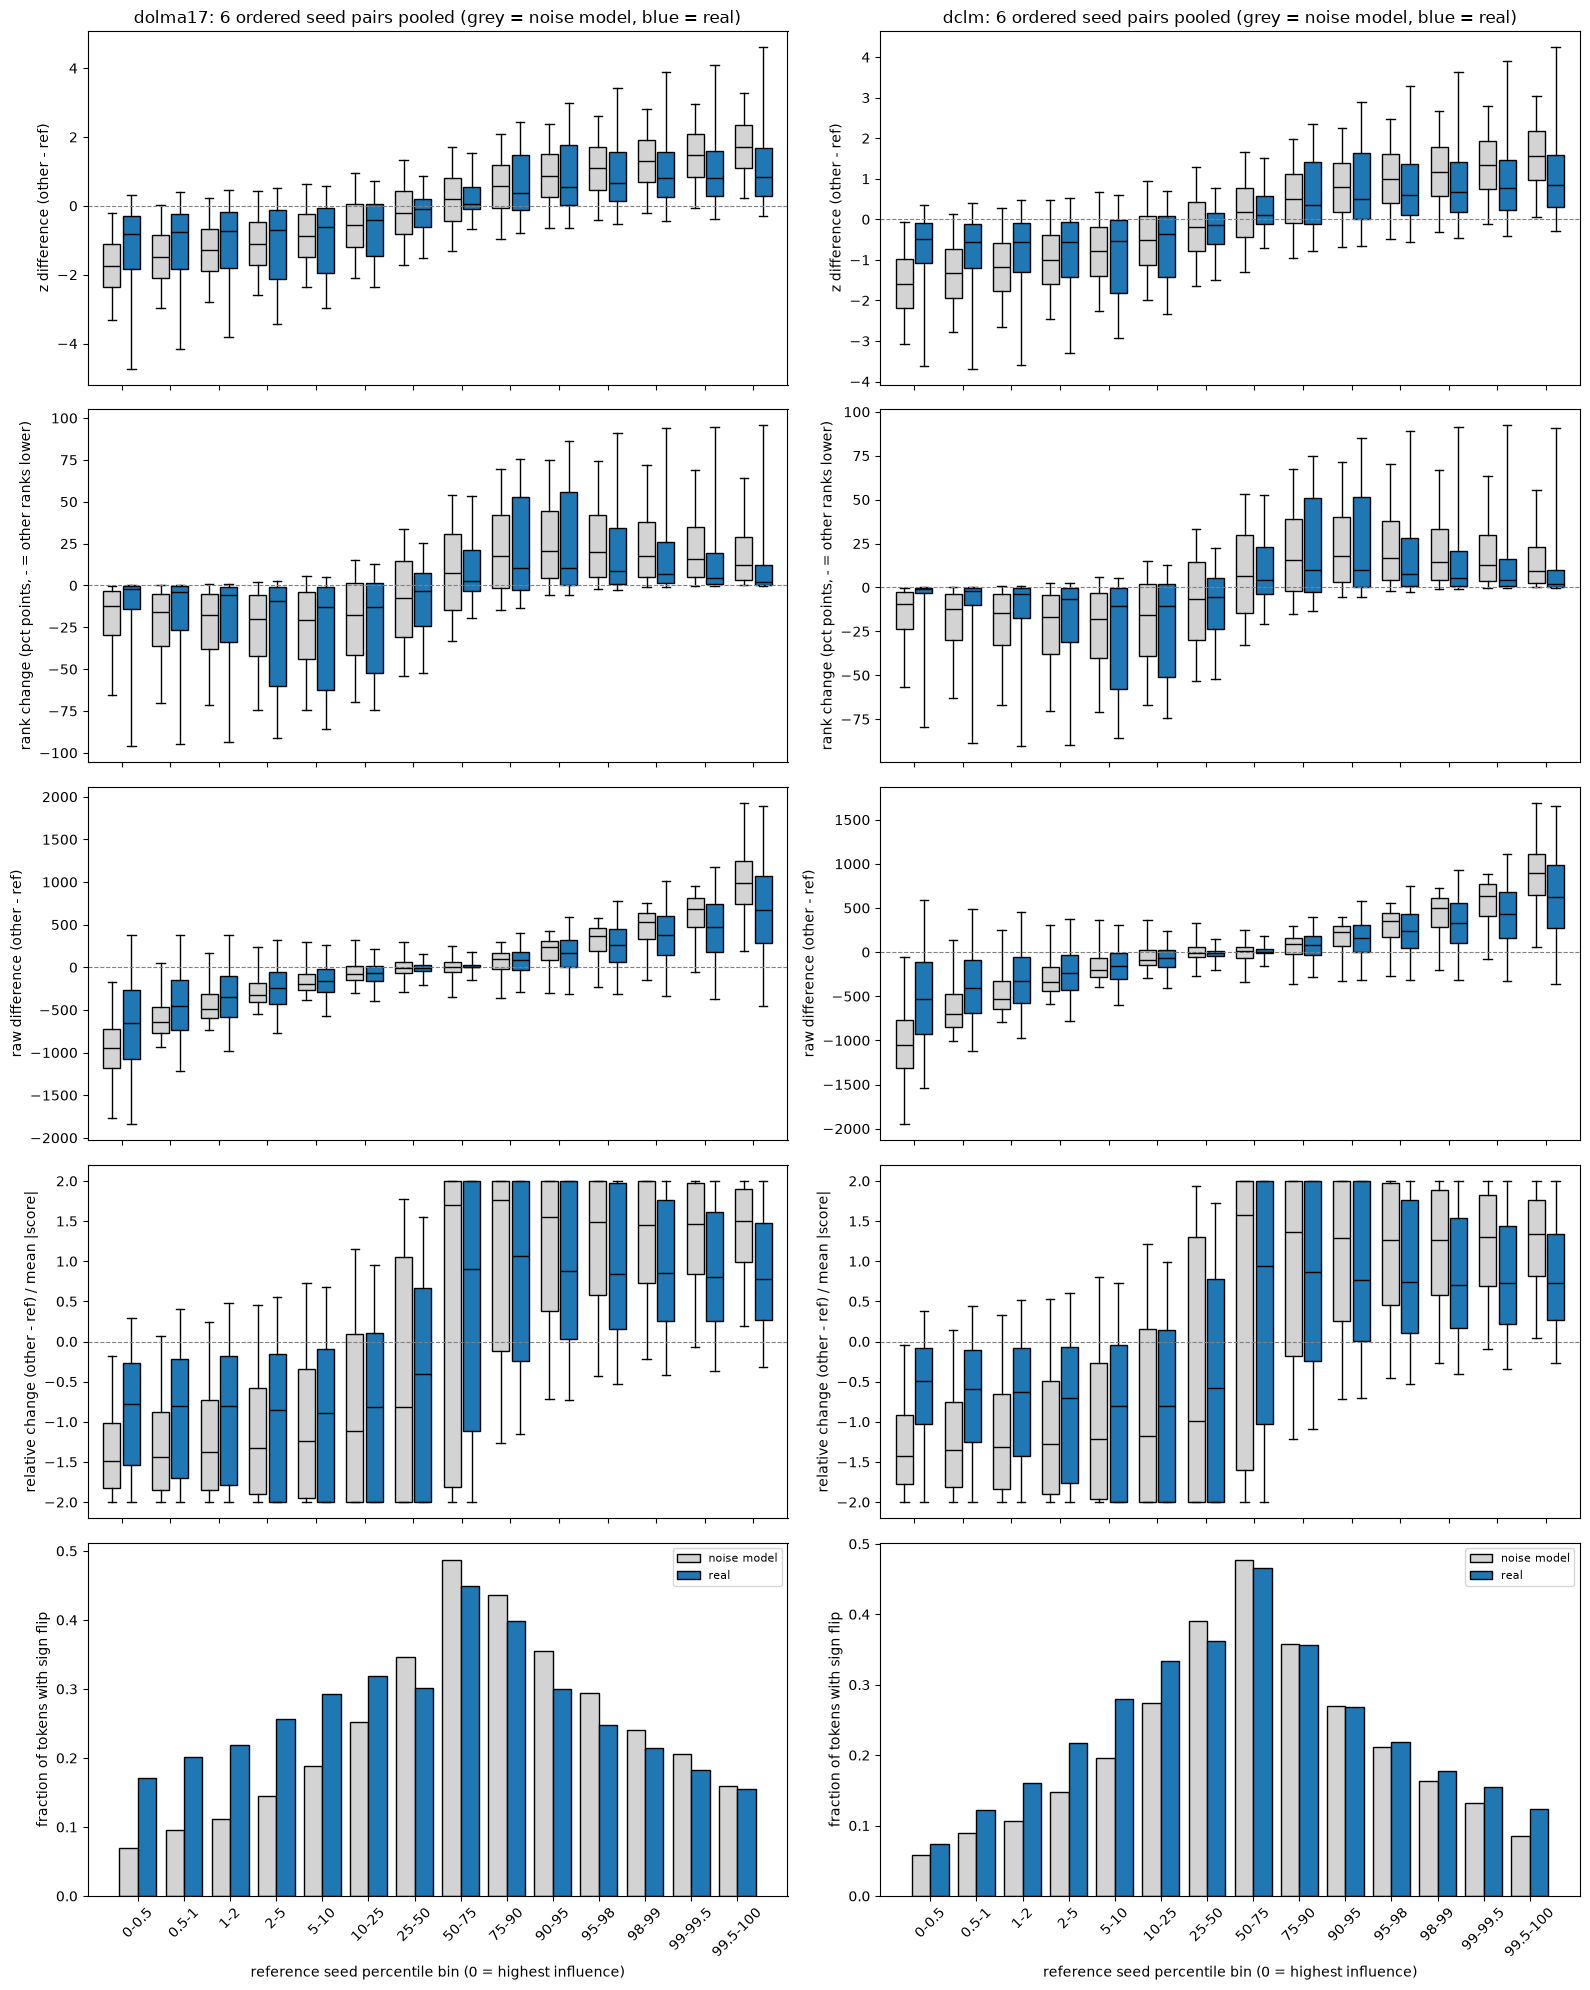

In [5]:
fig, axes = plt.subplots(len(PANELS) + 1, len(CORPORA), figsize=(8 * len(CORPORA), 4 * (len(PANELS) + 1)),
                         squeeze=False)
xs = np.arange(len(LABELS))
for col, (corpus, res) in enumerate(RESULTS.items()):
    for row, (key, ylabel) in enumerate(PANELS):
        ax = axes[row, col]
        for kind, shift, color in [("noise model", -0.2, "lightgray"), ("real", 0.2, "tab:blue")]:
            data = [res.loc[(res["kind"] == kind) & (res["bin"] == b), key].to_numpy() for b in LABELS]
            ax.boxplot(data, positions=xs + shift, widths=0.35, whis=(5, 95), showfliers=False,
                       patch_artist=True, boxprops={"facecolor": color}, medianprops={"color": "black"})
        ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_xticks(xs, [""] * len(LABELS))
        ax.set_ylabel(ylabel)
        if row == 0:
            ax.set_title(f"{corpus}: 6 ordered seed pairs pooled (grey = noise model, blue = real)")

    ax = axes[len(PANELS), col]
    flips = res.groupby(["bin", "kind"], observed=True)["flip"].mean().unstack("kind").reindex(LABELS)
    ax.bar(xs - 0.2, flips["noise model"], width=0.4, color="lightgray", edgecolor="black", label="noise model")
    ax.bar(xs + 0.2, flips["real"], width=0.4, color="tab:blue", edgecolor="black", label="real")
    ax.set_xticks(xs, LABELS, rotation=45)
    ax.set_xlabel("reference seed percentile bin (0 = highest influence)")
    ax.set_ylabel("fraction of tokens with sign flip")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Selection-free comparison: bin on seed A, compare seeds B and C

Binning on the seed that is compared builds in regression to the mean. Here seed A only picks the bin and the
two other seeds B and C are compared with each other: A's noise is independent of B's and C's, so within a
bin nothing is selected for B's or C's noise. Each of the 3 seeds takes the role of A once (pooled).

- **reproduced level**: mean z of B and C in the bin, against A's mean z. It is how much of A's extremity
  another seed reproduces; the ratio to A's level is the "retained share".
- **B vs C spread**: SD of z_B - z_C. Seed noise only (the true value cancels), so it shows whether noise
  differs between bins.
- **B vs C sign agreement**: share of tokens whose raw score has the same sign in B and C.

**Grey = noise model** for three seeds: z_s = sqrt(rho) T + sqrt(1 - rho) e_s with T, e_s standard normal,
rho = mean pairwise z correlation of the corpus; each fake seed is mapped by rank onto the matching real
seed's scores. It reproduces rho exactly but assumes Gaussian true values and the same noise for every
token, so its B vs C spread is sqrt(2 (1 - rho)) in every bin. Error bars: 95% document bootstrap.

In [6]:
N_BOOT = 200


def normal_scores(scores):
    return norm.ppf(1 - percentile(scores) / 100)


def triplet_frame(z, raw, docs):
    """z, raw: {seed: array}. One row per (token, choice of A), with B, C the other two seeds."""
    seeds = list(z)
    rows = []
    for a in seeds:
        b, c = [s for s in seeds if s != a]
        pct_a = 100 * (1 - norm.cdf(z[a]))
        rows.append(pd.DataFrame({
            "doc": docs, "bin": pd.cut(pct_a, EDGES, labels=LABELS, include_lowest=True),
            "z_a": z[a], "z_bc": (z[b] + z[c]) / 2, "d_bc": z[b] - z[c],
            "same_sign": np.sign(raw[b]) == np.sign(raw[c])}))
    return pd.concat(rows, ignore_index=True)


def fake_seeds(seeds, rho, rng):
    t = rng.standard_normal(len(dd))
    z, raw = {}, {}
    for s in seeds:
        zf = np.sqrt(rho) * t + np.sqrt(1 - rho) * rng.standard_normal(len(dd))
        order = np.argsort(np.argsort(-zf))
        raw[s] = np.sort(dd[s].to_numpy())[::-1][order]
        z[s] = norm.ppf(1 - (order + 0.5) / len(dd))
    return z, raw


def binned_stats(f, rng, n_boot=N_BOOT):
    """Per bin: mean z_a, mean z_bc, SD of d_bc, sign agreement, with a document bootstrap (95%)."""
    f = f.assign(d2=f["d_bc"] ** 2, same=f["same_sign"].astype(float))
    g = f.groupby(["doc", "bin"], observed=False)[["z_a", "z_bc", "d_bc", "d2", "same"]].agg(["sum", "count"])
    sums = {k: g[(k, "sum")].unstack("bin").reindex(columns=LABELS).fillna(0).to_numpy()
            for k in ["z_a", "z_bc", "d_bc", "d2", "same"]}
    n = g[("z_a", "count")].unstack("bin").reindex(columns=LABELS).fillna(0).to_numpy()

    def stats(w):
        cnt = w @ n
        mean = {k: (w @ sums[k]) / cnt for k in sums}
        return {"A level": mean["z_a"], "B,C level": mean["z_bc"], "retained": mean["z_bc"] / mean["z_a"],
                "B-C spread": np.sqrt(mean["d2"] - mean["d_bc"] ** 2), "sign agree": mean["same"]}

    point = stats(np.ones(len(n)))
    boots = [stats(rng.multinomial(len(n), np.full(len(n), 1 / len(n))).astype(float)) for _ in range(n_boot)]
    out = {}
    for k, v in point.items():
        b = np.array([x[k] for x in boots])
        out[k] = pd.DataFrame({"value": v, "lo": np.nanquantile(b, 0.025, axis=0),
                               "hi": np.nanquantile(b, 0.975, axis=0)}, index=LABELS)
    return pd.concat(out, axis=1)


rng = np.random.default_rng(1)
TRIPLET, TRIPLET_RHO = {}, {}
docs = dd["document"].to_numpy()
for corpus, seeds in CORPORA.items():
    z = {s: normal_scores(dd[s]) for s in seeds}
    raw = {s: dd[s].to_numpy() for s in seeds}
    rho = np.mean([np.corrcoef(z[a], z[b])[0, 1] for a, b in permutations(seeds, 2)])
    TRIPLET_RHO[corpus] = rho
    zf, rawf = fake_seeds(seeds, rho, rng)
    TRIPLET[corpus] = {"real": binned_stats(triplet_frame(z, raw, docs), rng),
                       "noise model": binned_stats(triplet_frame(zf, rawf, docs), rng)}
    t = pd.concat({kind: s.xs("value", axis=1, level=1) for kind, s in TRIPLET[corpus].items()}, axis=1)
    print(f"=== {corpus}: mean pairwise rho {rho:.3f}; noise-model B-C spread {np.sqrt(2 * (1 - rho)):.3f} ===")
    display(t.swaplevel(axis=1).sort_index(axis=1, level=0).round(3))

=== dolma17: mean pairwise rho 0.400; noise-model B-C spread 1.095 ===


A level          B,C level         B-C spread           retained  \
         noise model   real noise model   real noise model   real noise model   
0-0.5          2.892  2.892       1.180  1.539       1.092  1.791       0.408   
0.5-1          2.439  2.439       0.971  1.201       1.083  1.614       0.398   
1-2            2.177  2.177       0.856  1.033       1.099  1.566       0.393   
2-5            1.824  1.824       0.727  0.761       1.090  1.481       0.398   
5-10           1.447  1.447       0.581  0.520       1.094  1.358       0.402   
10-25          0.949  0.949       0.381  0.305       1.092  1.170       0.402   
25-50          0.325  0.325       0.129  0.115       1.094  0.862       0.398   
50-75         -0.325 -0.325      -0.129 -0.090       1.096  0.761       0.398   
75-90         -0.949 -0.949      -0.378 -0.304       1.096  1.251       0.399   
90-95         -1.447 -1.447      -0.584 -0.598       1.094  1.402       0.404   
95-98         -1.824 -1.824      -0.729 -0.827       1.101  1.480       0.400   
98-99         -2.177 -2.177      -0.880 -1.024       1.095  1.586       0.404   
99-99.5       -2.439 -2.439      -0.976 -1.251       1.101  1.606       0.400   
99.5-100      -2.892 -2.892      -1.170 -1.611       1.080  1.722       0.405   

                 sign agree         
           real noise model   real  
0-0.5     0.532       0.898  0.778  
0.5-1     0.493       0.844  0.759  
1-2       0.475       0.814  0.738  
2-5       0.417       0.783  0.703  
5-10      0.360       0.741  0.675  
10-25     0.321       0.686  0.655  
25-50     0.355       0.629  0.671  
50-75     0.279       0.596  0.624  
75-90     0.320       0.598  0.611  
90-95     0.413       0.629  0.654  
95-98     0.453       0.657  0.696  
98-99     0.470       0.689  0.725  
99-99.5   0.513       0.719  0.752  
99.5-100  0.557       0.777  0.790

=== dclm: mean pairwise rho 0.457; noise-model B-C spread 1.043 ===


A level          B,C level         B-C spread           retained  \
         noise model   real noise model   real noise model   real noise model   
0-0.5          2.892  2.892       1.302  2.101       1.079  1.221       0.450   
0.5-1          2.439  2.439       1.106  1.554       1.039  1.351       0.453   
1-2            2.177  2.177       1.002  1.269       1.053  1.360       0.460   
2-5            1.824  1.824       0.827  0.916       1.041  1.372       0.453   
5-10           1.447  1.447       0.658  0.593       1.042  1.305       0.455   
10-25          0.949  0.949       0.436  0.329       1.042  1.150       0.460   
25-50          0.325  0.325       0.150  0.086       1.041  0.809       0.462   
50-75         -0.325 -0.325      -0.148 -0.078       1.043  0.779       0.457   
75-90         -0.949 -0.949      -0.435 -0.349       1.038  1.179       0.458   
90-95         -1.447 -1.447      -0.660 -0.658       1.045  1.313       0.456   
95-98         -1.824 -1.824      -0.836 -0.910       1.042  1.387       0.458   
98-99         -2.177 -2.177      -1.002 -1.172       1.044  1.419       0.460   
99-99.5       -2.439 -2.439      -1.130 -1.352       1.033  1.475       0.464   
99.5-100      -2.892 -2.892      -1.327 -1.708       1.027  1.539       0.459   

                 sign agree         
           real noise model   real  
0-0.5     0.726       0.897  0.893  
0.5-1     0.637       0.863  0.830  
1-2       0.583       0.836  0.793  
2-5       0.502       0.788  0.738  
5-10      0.410       0.738  0.689  
10-25     0.347       0.677  0.650  
25-50     0.266       0.618  0.624  
50-75     0.240       0.602  0.594  
75-90     0.368       0.632  0.639  
90-95     0.454       0.678  0.690  
95-98     0.499       0.726  0.730  
98-99     0.538       0.777  0.774  
99-99.5   0.554       0.817  0.792  
99.5-100  0.591       0.859  0.823

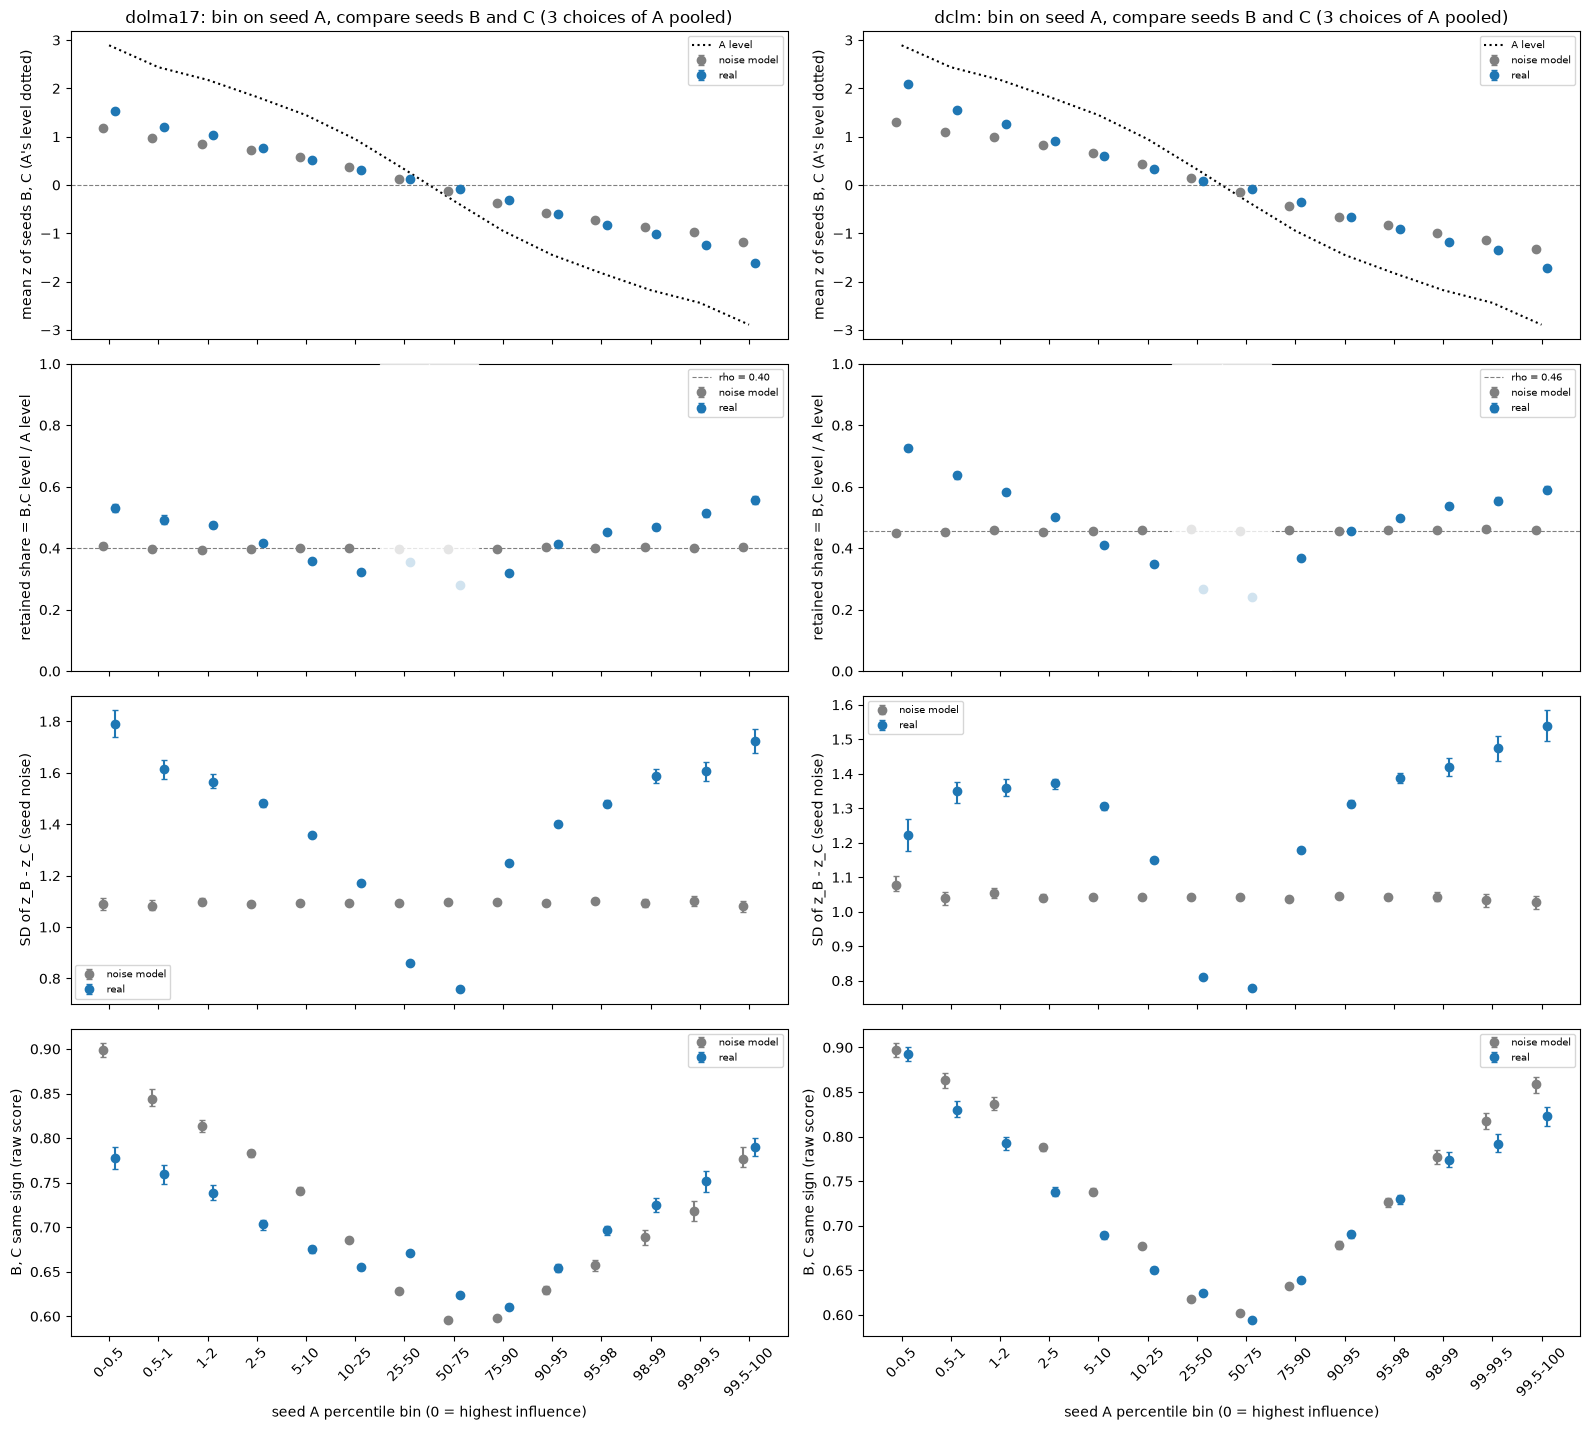

In [7]:
PANELS_T = [("B,C level", "mean z of seeds B, C (A's level dotted)"),
            ("retained", "retained share = B,C level / A level"),
            ("B-C spread", "SD of z_B - z_C (seed noise)"),
            ("sign agree", "B, C same sign (raw score)")]
fig, axes = plt.subplots(len(PANELS_T), len(CORPORA), figsize=(8 * len(CORPORA), 3.6 * len(PANELS_T)),
                         squeeze=False, sharex=True)
xs = np.arange(len(LABELS))
for col, corpus in enumerate(CORPORA):
    for row, (key, ylabel) in enumerate(PANELS_T):
        ax = axes[row, col]
        for kind, shift, color in [("noise model", -0.12, "gray"), ("real", 0.12, "tab:blue")]:
            s = TRIPLET[corpus][kind][key]
            ax.errorbar(xs + shift, s["value"], yerr=[s["value"] - s["lo"], s["hi"] - s["value"]],
                        fmt="o", color=color, capsize=2, label=kind)
        if key == "B,C level":
            ax.plot(xs, TRIPLET[corpus]["real"]["A level"]["value"], ":", color="black", label="A level")
            ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
        if key == "retained":
            ax.axhline(TRIPLET_RHO[corpus], color="gray", linestyle="--", linewidth=0.8,
                       label=f"rho = {TRIPLET_RHO[corpus]:.2f}")
            mid = [LABELS.index("25-50"), LABELS.index("50-75")]
            ax.set_ylim(0, 1)
            for m in mid:
                ax.axvspan(m - 0.5, m + 0.5, color="white", zorder=3, alpha=0.8)
        ax.set_ylabel(ylabel)
        if row == 0:
            ax.set_title(f"{corpus}: bin on seed A, compare seeds B and C (3 choices of A pooled)")
        ax.legend(fontsize=7)
    axes[-1, col].set_xticks(xs, LABELS, rotation=45)
    axes[-1, col].set_xlabel("seed A percentile bin (0 = highest influence)")
plt.tight_layout()
plt.show()

## Pairwise joint distributions

Every token as one point per seed pair, nothing binned (so no selection effect). Colour = token count per
hexagon on a log scale, so the sparse tails stay visible next to the dense core; read counts from the
colour bar.

- **z rows**: each seed's rank as a normal score. Dashed = y = x (perfect agreement), dotted = y = rho x,
  the noise model's expected other-seed score. A band of constant width around the dotted line is what the
  noise model predicts; a wedge that widens toward the corners means noise grows with the score.
- **raw rows**: the raw IF scores on a signed log scale, sign(s) log10(1 + |s| / c) with c = the corpus'
  median |score|, so both signs and the heavy tails fit. Points off the diagonal quadrants are sign flips.

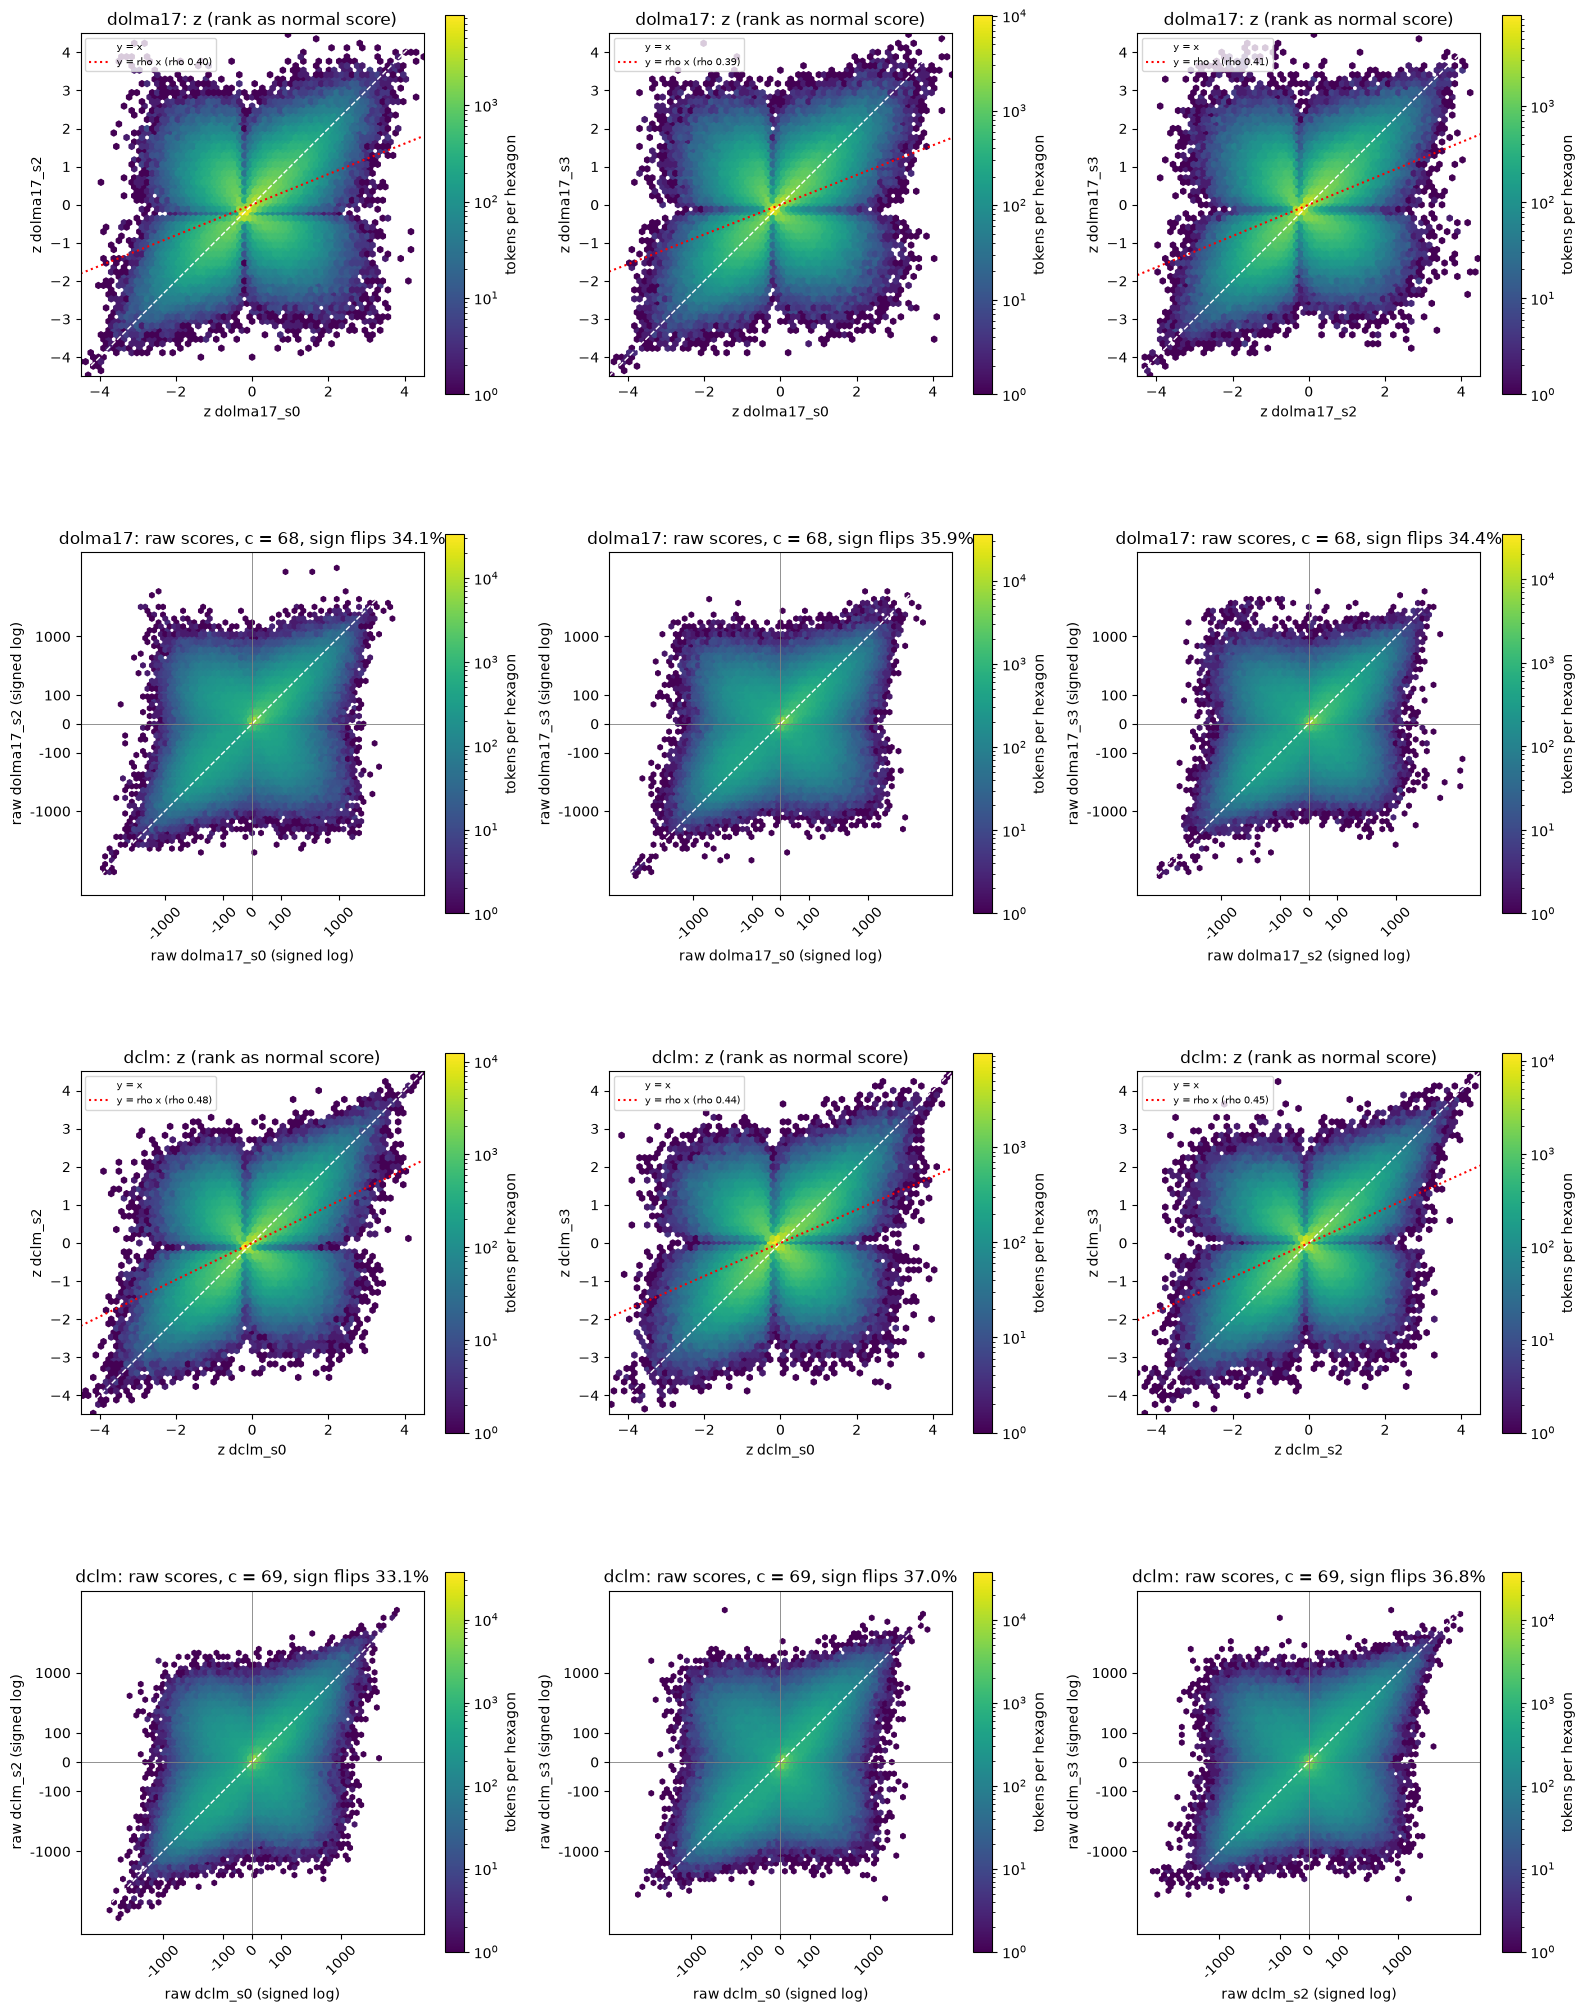

In [8]:
from itertools import combinations

from matplotlib.colors import LogNorm


def signed_log(x, c):
    return np.sign(x) * np.log10(1 + np.abs(x) / c)


def signed_log_ticks(ax, c, lim):
    vals = np.array([v for v in [0, 1e2, 1e3, 1e4] if signed_log(v, c) <= lim])
    vals = np.concatenate([-vals[:0:-1], vals])
    pos = signed_log(vals, c)
    labels = [f"{v:g}" for v in vals]
    ax.set_xticks(pos, labels, rotation=45)
    ax.set_yticks(pos, labels)


pairs_of = {corpus: list(combinations(seeds, 2)) for corpus, seeds in CORPORA.items()}
fig, axes = plt.subplots(2 * len(CORPORA), 3, figsize=(16, 10.5 * len(CORPORA)), squeeze=False)
for k, (corpus, seeds) in enumerate(CORPORA.items()):
    z = {s: normal_scores(dd[s]) for s in seeds}
    c = np.median(np.abs(dd[seeds].to_numpy()))
    lim_raw = max(np.abs(signed_log(dd[s].to_numpy(), c)).max() for s in seeds)
    for j, (a, b) in enumerate(pairs_of[corpus]):
        rho = np.corrcoef(z[a], z[b])[0, 1]
        ax = axes[2 * k, j]
        hb = ax.hexbin(z[a], z[b], gridsize=70, norm=LogNorm(), cmap="viridis", mincnt=1)
        grid = np.array([-4.5, 4.5])
        ax.plot(grid, grid, "--", color="white", linewidth=1, label="y = x")
        ax.plot(grid, rho * grid, ":", color="red", linewidth=1.5, label=f"y = rho x (rho {rho:.2f})")
        ax.set_xlim(-4.5, 4.5)
        ax.set_ylim(-4.5, 4.5)
        ax.set_aspect("equal")
        ax.set_xlabel(f"z {a}")
        ax.set_ylabel(f"z {b}")
        ax.set_title(f"{corpus}: z (rank as normal score)")
        ax.legend(fontsize=7, loc="upper left")
        fig.colorbar(hb, ax=ax, shrink=0.8, label="tokens per hexagon")

        ax = axes[2 * k + 1, j]
        ra, rb = signed_log(dd[a].to_numpy(), c), signed_log(dd[b].to_numpy(), c)
        hb = ax.hexbin(ra, rb, gridsize=70, norm=LogNorm(), cmap="viridis", mincnt=1,
                       extent=(-lim_raw, lim_raw, -lim_raw, lim_raw))
        ax.plot([-lim_raw, lim_raw], [-lim_raw, lim_raw], "--", color="white", linewidth=1)
        ax.axhline(0, color="gray", linewidth=0.6)
        ax.axvline(0, color="gray", linewidth=0.6)
        ax.set_aspect("equal")
        signed_log_ticks(ax, c, lim_raw)
        flips = np.mean(np.sign(dd[a]) != np.sign(dd[b]))
        ax.set_xlabel(f"raw {a} (signed log)")
        ax.set_ylabel(f"raw {b} (signed log)")
        ax.set_title(f"{corpus}: raw scores, c = {c:.0f}, sign flips {flips:.1%}")
        fig.colorbar(hb, ax=ax, shrink=0.8, label="tokens per hexagon")
plt.tight_layout()
plt.show()

## Two bumps: same-sign and opposite-sign lines

Away from zero, each vertical slice of the z plots has two bumps: one where the second seed gives the same sign
(quadrants 1 and 3) and a smaller one where it flips the sign (quadrants 2 and 4). Fit one line per bump:

- both axes shifted so a raw score of 0 sits at 0 (the dark cross);
- x slices of width 0.25; in each slice the median of y above 0 and the median of y below 0 (the bump centres;
  the empty band between the bumps makes the split at y = 0 cut off little);
- a line through the origin per quadrant, on slices with |x| >= 1 only (closer to 0 there is one cluster,
  not two bumps);
- **same-sign slope** = mean of Q1 and Q3, **opposite-sign slope** = mean of Q2 and Q4 (sign flipped), and
  their ratio. Noise in x flattens both slopes equally, so the ratio is the robust number: 1 = a flipped token
  keeps its size (clean mirror image), < 1 = flipped tokens are also smaller.

95% document bootstrap. The right column shows the share of tokens in the same-sign bump per x slice.

In [9]:
X_MIN, WIDTH, N_BOOT_FIT = 1.0, 0.25, 200
EDGES_X = np.arange(-4.5, 4.5 + 1e-9, WIDTH)
CENTRES_X = (EDGES_X[:-1] + EDGES_X[1:]) / 2
USE_X = np.abs(CENTRES_X) >= X_MIN
QUADRANTS = {"Q1 (+,+)": (1, "up"), "Q4 (+,-)": (1, "dn"), "Q3 (-,-)": (-1, "dn"), "Q2 (-,+)": (-1, "up")}


def shifted_z(scores):
    """Rank as normal score, shifted so that a raw score of 0 sits at 0."""
    return normal_scores(scores) - norm.ppf(1 - (scores > 0).mean())


def wmedian(v, w):
    o = np.argsort(v)
    cw = np.cumsum(w[o])
    return v[o][np.searchsorted(cw, cw[-1] / 2)] if len(v) and cw[-1] > 0 else np.nan


def bump_table(x, y, slice_of, w):
    rows = []
    for k, c in enumerate(CENTRES_X):
        m = slice_of == k
        up, dn = m & (y > 0), m & (y < 0)
        same = up if c > 0 else dn
        rows.append({"x": c, "up": wmedian(y[up], w[up]), "dn": wmedian(y[dn], w[dn]),
                     "same_share": w[same].sum() / w[m].sum() if w[m].sum() else np.nan})
    return pd.DataFrame(rows)


def bump_slopes(t):
    t = t[USE_X]
    out = {}
    for name, (side, col) in QUADRANTS.items():
        sel = (np.sign(t["x"]) == side) & t[col].notna()
        xs, ys = t["x"][sel].to_numpy(), t[col][sel].to_numpy()
        out[name] = (xs @ ys) / (xs @ xs)
    out["same sign"] = (out["Q1 (+,+)"] + out["Q3 (-,-)"]) / 2
    out["opposite sign"] = -(out["Q2 (-,+)"] + out["Q4 (+,-)"]) / 2
    out["ratio"] = out["opposite sign"] / out["same sign"]
    return out


rng = np.random.default_rng(2)
doc_codes, doc_ids = pd.factorize(dd["document"])
BUMP = {}
for corpus, seeds in CORPORA.items():
    for a, b in combinations(seeds, 2):
        x, y = shifted_z(dd[a]), shifted_z(dd[b])
        slice_of = np.digitize(x, EDGES_X) - 1
        table = bump_table(x, y, slice_of, np.ones(len(x)))
        boot_tables = [bump_table(x, y, slice_of, rng.multinomial(len(doc_ids), np.full(len(doc_ids), 1 / len(doc_ids)))
                                  [doc_codes].astype(float)) for _ in range(N_BOOT_FIT)]
        boots = pd.DataFrame([bump_slopes(t) for t in boot_tables])
        stack = np.stack([t[["up", "dn", "same_share"]].to_numpy() for t in boot_tables])
        BUMP[(corpus, a, b)] = {"x": x, "y": y, "table": table, "slopes": pd.Series(bump_slopes(table)),
                                "lo": boots.quantile(0.025), "hi": boots.quantile(0.975),
                                "t_lo": np.nanquantile(stack, 0.025, axis=0), "t_hi": np.nanquantile(stack, 0.975, axis=0)}

summary = pd.DataFrame({f"{a} vs {b}": {k: f"{v['slopes'][k]:+.2f} [{v['lo'][k]:+.2f}, {v['hi'][k]:+.2f}]"
                                         for k in v["slopes"].index}
                        for (corpus, a, b), v in BUMP.items()}).T
summary

/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


,"Q1 (+,+)","Q4 (+,-)","Q3 (-,-)","Q2 (-,+)",same sign,opposite sign,ratio
dolma17_s0 vs dolma17_s2,"+0.82 [+0.79, +0.85]","-0.37 [-0.44, -0.29]","+0.85 [+0.80, +0.88]","-0.56 [-0.74, -0.54]","+0.84 [+0.81, +0.86]","+0.46 [+0.44, +0.56]","+0.56 [+0.52, +0.68]"
dolma17_s0 vs dolma17_s3,"+0.76 [+0.72, +0.79]","-0.39 [-0.47, -0.33]","+0.86 [+0.81, +0.89]","-0.52 [-0.65, -0.48]","+0.81 [+0.78, +0.83]","+0.46 [+0.42, +0.54]","+0.56 [+0.52, +0.67]"
dolma17_s2 vs dolma17_s3,"+0.80 [+0.72, +0.81]","-0.33 [-0.38, -0.24]","+0.88 [+0.85, +0.91]","-0.54 [-0.68, -0.50]","+0.84 [+0.81, +0.86]","+0.43 [+0.39, +0.51]","+0.51 [+0.46, +0.61]"
dclm_s0 vs dclm_s2,"+0.82 [+0.78, +0.85]","-0.33 [-0.35, -0.29]","+0.89 [+0.86, +0.92]","-0.47 [-0.53, -0.41]","+0.86 [+0.82, +0.88]","+0.40 [+0.36, +0.42]","+0.47 [+0.42, +0.50]"
dclm_s0 vs dclm_s3,"+0.78 [+0.71, +0.79]","-0.35 [-0.48, -0.32]","+0.86 [+0.82, +0.89]","-0.52 [-0.57, -0.42]","+0.82 [+0.78, +0.84]","+0.44 [+0.38, +0.50]","+0.53 [+0.46, +0.61]"
dclm_s2 vs dclm_s3,"+0.86 [+0.84, +0.87]","-0.46 [-0.53, -0.38]","+0.83 [+0.80, +0.87]","-0.45 [-0.49, -0.41]","+0.85 [+0.83, +0.86]","+0.46 [+0.41, +0.49]","+0.54 [+0.48, +0.59]"


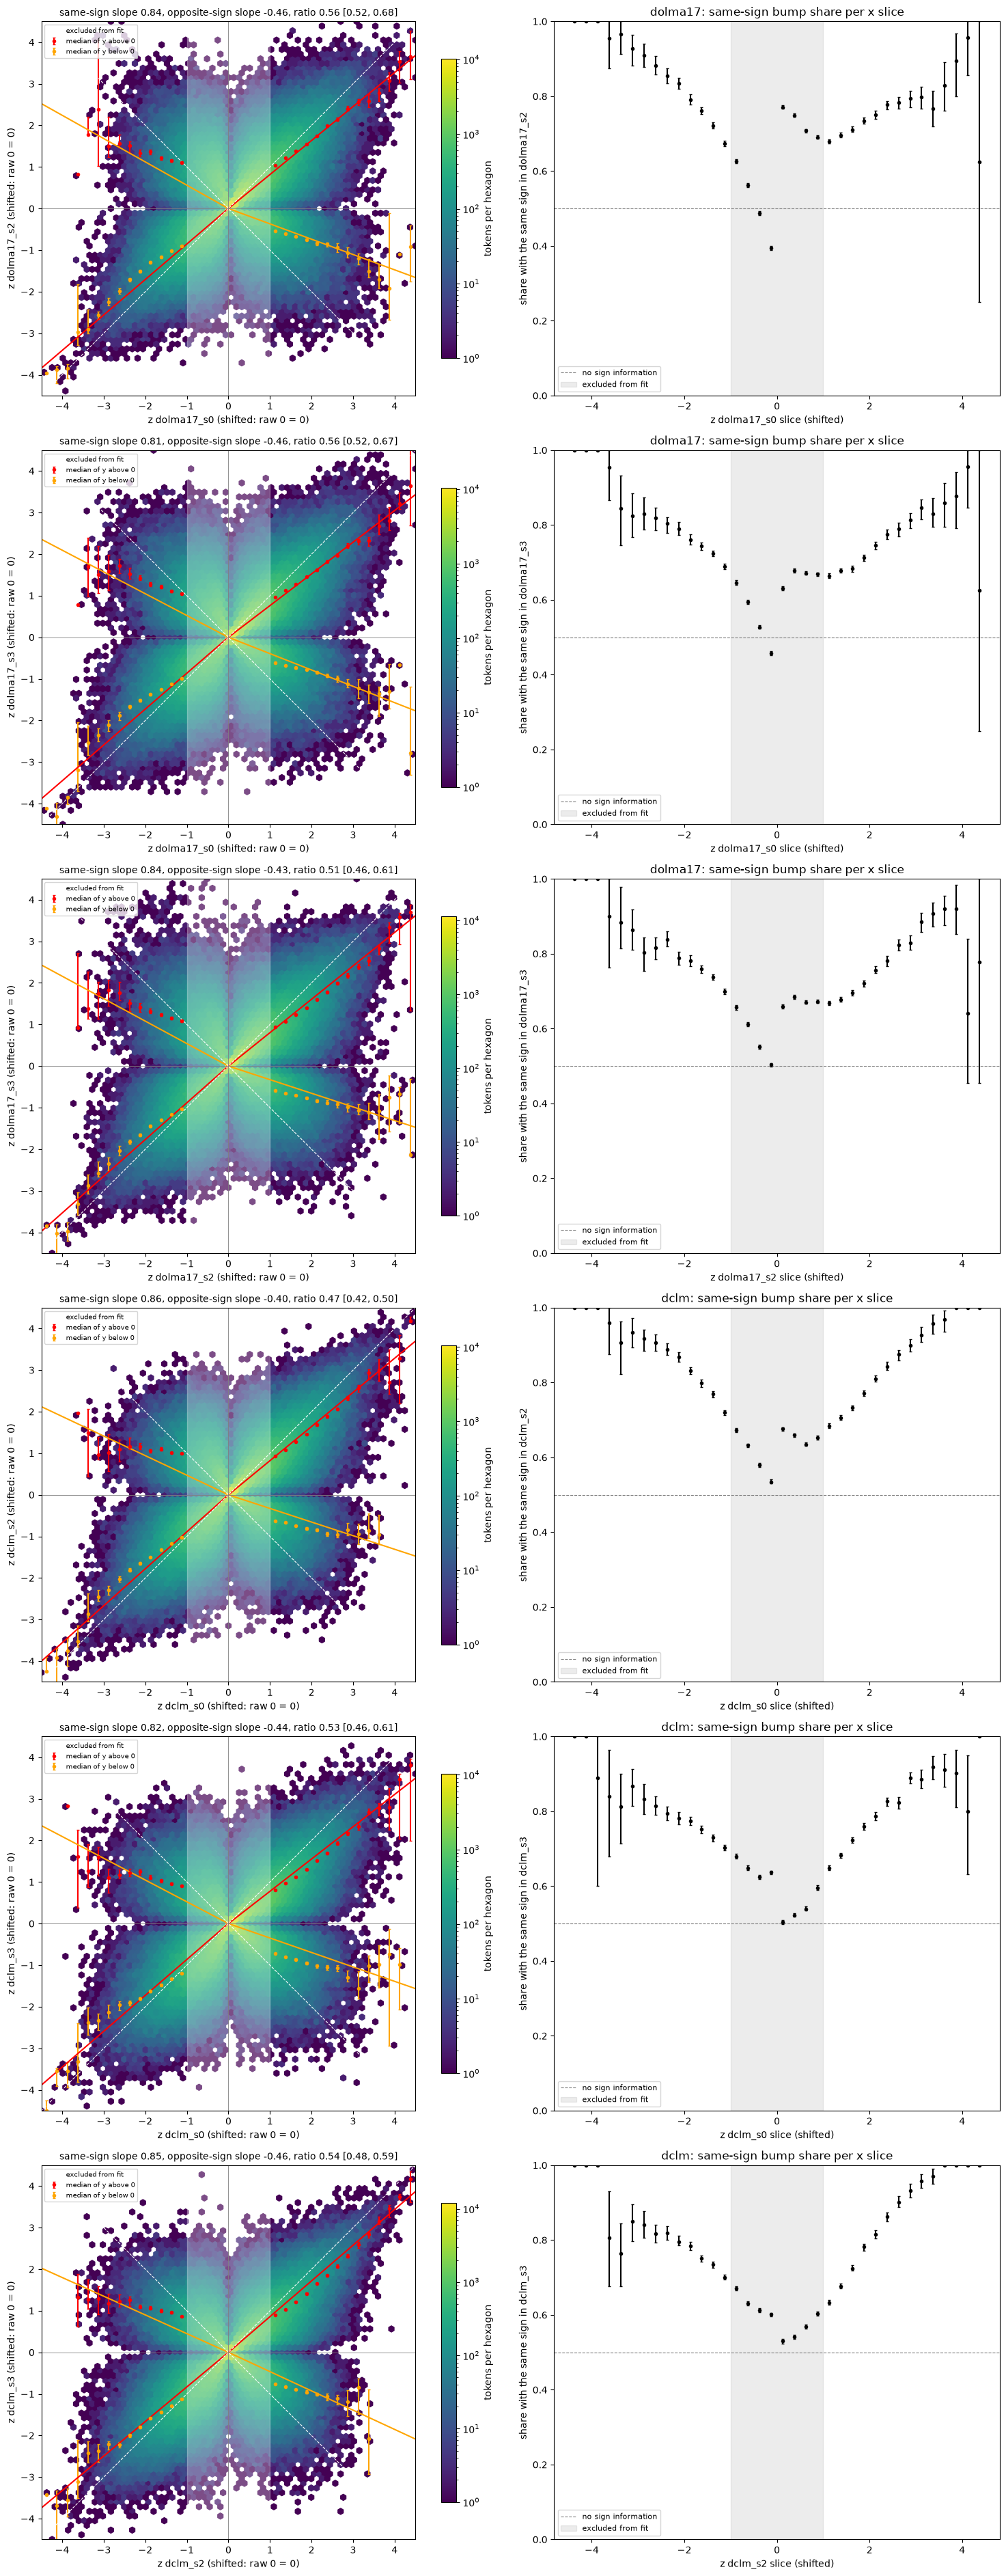

In [10]:
n_pairs = len(BUMP)
fig, axes = plt.subplots(n_pairs, 2, figsize=(15, 6.3 * n_pairs), squeeze=False, gridspec_kw={"width_ratios": [1.15, 1]})
g = np.array([0, 4.5])
for row, ((corpus, a, b), v) in zip(axes, BUMP.items()):
    ax, ax2 = row
    x, y, t, s = v["x"], v["y"], v["table"], v["slopes"]
    hb = ax.hexbin(x, y, gridsize=70, norm=LogNorm(), cmap="viridis", mincnt=1, extent=(-4.5, 4.5, -4.5, 4.5))
    fig.colorbar(hb, ax=ax, shrink=0.8, label="tokens per hexagon")
    ax.axvspan(-X_MIN, X_MIN, color="white", alpha=0.3, label="excluded from fit")
    for i, (col, color, label) in enumerate([("up", "red", "median of y above 0"), ("dn", "orange", "median of y below 0")]):
        ax.errorbar(t["x"][USE_X], t[col][USE_X], fmt="o", ms=3, color=color, capsize=1.5, label=label,
                    yerr=[(t[col] - v["t_lo"][:, i])[USE_X], (v["t_hi"][:, i] - t[col])[USE_X]])
    for name, (side, col) in QUADRANTS.items():
        ax.plot(side * g, s[name] * side * g, "-", color="red" if col == ("up" if side > 0 else "dn") else "orange",
                linewidth=1.5)
    ax.plot([-4.5, 4.5], [-4.5, 4.5], "--", color="white", linewidth=0.8)
    ax.plot([-4.5, 4.5], [4.5, -4.5], "--", color="white", linewidth=0.8)
    ax.axhline(0, color="gray", linewidth=0.6)
    ax.axvline(0, color="gray", linewidth=0.6)
    ax.set_xlim(-4.5, 4.5)
    ax.set_ylim(-4.5, 4.5)
    ax.set_aspect("equal")
    ax.set_xlabel(f"z {a} (shifted: raw 0 = 0)")
    ax.set_ylabel(f"z {b} (shifted: raw 0 = 0)")
    ax.set_title(f"same-sign slope {s['same sign']:.2f}, opposite-sign slope {-s['opposite sign']:.2f}, "
                 f"ratio {s['ratio']:.2f} [{v['lo']['ratio']:.2f}, {v['hi']['ratio']:.2f}]", fontsize=10)
    ax.legend(fontsize=7, loc="upper left")

    ax2.errorbar(t["x"], t["same_share"], fmt="o", ms=3, color="black", capsize=1.5,
                 yerr=[t["same_share"] - v["t_lo"][:, 2], v["t_hi"][:, 2] - t["same_share"]])
    ax2.axhline(0.5, color="gray", linestyle="--", linewidth=0.8, label="no sign information")
    ax2.axvspan(-X_MIN, X_MIN, color="gray", alpha=0.15, label="excluded from fit")
    ax2.set_ylim(0, 1)
    ax2.set_xlabel(f"z {a} slice (shifted)")
    ax2.set_ylabel(f"share with the same sign in {b}")
    ax2.set_title(f"{corpus}: same-sign bump share per x slice")
    ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()